In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy.sparse import hstack, csr_matrix, save_npz

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import TruncatedSVD

import joblib

%matplotlib inline

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [2]:
PROJECT_DIR = Path.cwd().parent

OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = OUTPUT_DIR / "meajor_cleaned.csv"

print("Project directory:", PROJECT_DIR)
print("Input file:", DATA_PATH)
print("Output directory:", OUTPUT_DIR)

Project directory: d:\spamEmail\unsaturated
Input file: d:\spamEmail\unsaturated\outputs\meajor_cleaned.csv
Output directory: d:\spamEmail\unsaturated\outputs


In [3]:
df_clean = pd.read_csv(DATA_PATH)

print("Dataset shape:", df_clean.shape)

df_clean.head()

Dataset shape: (108671, 20)


,sender,sender_domain,receiver,receiver_domain,date,subject,content_types,body,urls,url_count,url_length_max,url_length_avg,url_subdom_max,url_subdom_avg,attachment_count,has_attachments,attachment_types,language,source,label
0,d66e9e64b006d6bca649f1c945129c42c43836872b2ead...,enron.com,35c5a9fb9fba3b8737ed7cef2a87e427a73db4fca85f6b...,enron.com,2001-06-29 09:37:04-05:00,[ORGANIZATION] failover plan.,text/plain,"Hi [NAME], \n\nTonight we are rolling out a n...",NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
1,0907d5c64598aa2639154ed4e1556be615669e40052a1f...,enron.com,aa2c35499eae5999bf6080453cc719a891da2bb0c3803d...,enron.com,2001-06-29 08:39:30-05:00,RE: Intranet Site,text/plain,"[NAME] r these new?\tIntranet Site\n\n[NAME],\...",http://eastpower.dev.corp.enron.com/summary/pj...,3.0,60.0,58.0,3.0,3.0,0.0,False,NaN,en,trec5,0.0
2,7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20...,enron.com,a736837579feb601fbf6c0657d3d93689774afa6491bb9...,enron.com;enron.com,2001-06-29 10:35:17-05:00,FW: [ORGANIZATION] Company information,text/plain,"[NAME]/[NAME],\n\nWe are currently trading und...",NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
3,8531d54a169c4af106b9ea2165d4986b8cc10fc0a6bb9b...,enron.com,765a3ec4a67e40118d22de5729b05d090a1b59cb443bf6...,enron.com;enron.com,2001-06-29 10:40:02-05:00,New Master Physical,text/plain,[NAME] and [NAME] -\n\nAttached is a worksheet...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
4,7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20...,enron.com,ce418c97ac415706338972e1dbbd99ebb8c617b5c937a3...,enron.com;enron.com;enron.com,2001-06-29 10:48:00-05:00,FW: [ORGANIZATION]/Mirant GISB,text/plain,FYI. Below is a copy of my communication with ...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0


In [4]:
df_clean["email_text"] = (
    df_clean["subject"].fillna("").astype(str)
    + " "
    + df_clean["body"].fillna("").astype(str)
)

df_clean[["subject", "body", "email_text"]].head()

,subject,body,email_text
0,[ORGANIZATION] failover plan.,"Hi [NAME], \n\nTonight we are rolling out a n...","[ORGANIZATION] failover plan. Hi [NAME], \n\n..."
1,RE: Intranet Site,"[NAME] r these new?\tIntranet Site\n\n[NAME],\...",RE: Intranet Site [NAME] r these new?\tIntrane...
2,FW: [ORGANIZATION] Company information,"[NAME]/[NAME],\n\nWe are currently trading und...",FW: [ORGANIZATION] Company information [NAME]/...
3,New Master Physical,[NAME] and [NAME] -\n\nAttached is a worksheet...,New Master Physical [NAME] and [NAME] -\n\nAtt...
4,FW: [ORGANIZATION]/Mirant GISB,FYI. Below is a copy of my communication with ...,FW: [ORGANIZATION]/Mirant GISB FYI. Below is a...


In [5]:
df_clean["text_length"] = df_clean["email_text"].str.len()

df_clean["text_length"].describe()

count    108671.000000
mean       1211.201949
std        1141.671382
min           4.000000
25%         419.000000
50%         839.000000
75%        1572.000000
max       31135.000000
Name: text_length, dtype: float64

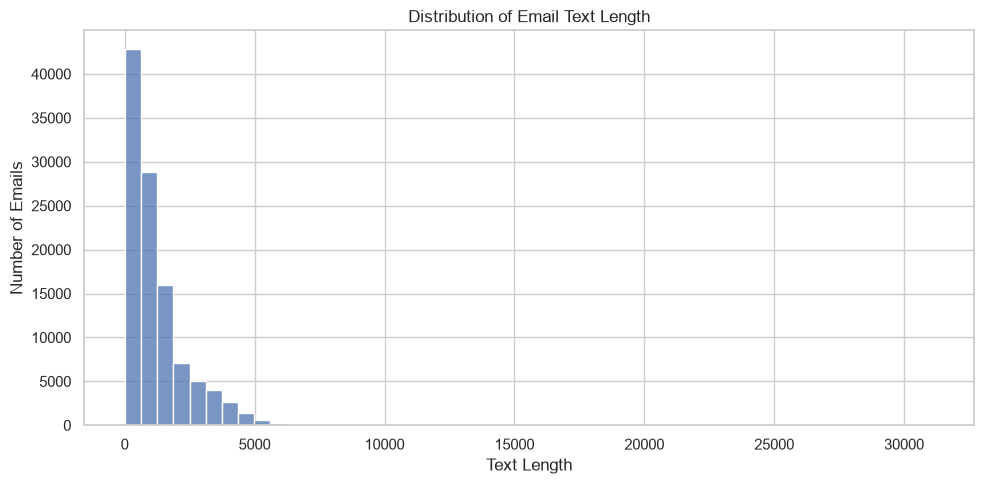

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean["text_length"],
    bins=50
)

plt.title("Distribution of Email Text Length")
plt.xlabel("Text Length")
plt.ylabel("Number of Emails")
plt.tight_layout()
plt.show()

In [7]:
numerical_columns = [
    "url_count",
    "url_length_max",
    "url_length_avg",
    "url_subdom_max",
    "url_subdom_avg",
    "attachment_count",
    "text_length"
]

X_num = df_clean[numerical_columns].copy()

print("Numerical feature shape:", X_num.shape)

X_num.head()

Numerical feature shape: (108671, 7)


,url_count,url_length_max,url_length_avg,url_subdom_max,url_subdom_avg,attachment_count,text_length
0,0.0,0.0,0.0,0.0,0.0,0.0,604
1,3.0,60.0,58.0,3.0,3.0,0.0,290
2,0.0,0.0,0.0,0.0,0.0,0.0,1152
3,0.0,0.0,0.0,0.0,0.0,0.0,298
4,0.0,0.0,0.0,0.0,0.0,0.0,871


In [8]:
url_max_cap = X_num["url_length_max"].quantile(0.999)
url_avg_cap = X_num["url_length_avg"].quantile(0.999)

print("URL maximum length cap:", url_max_cap)
print("URL average length cap:", url_avg_cap)

X_num["url_length_max"] = X_num["url_length_max"].clip(
    upper=url_max_cap
)

X_num["url_length_avg"] = X_num["url_length_avg"].clip(
    upper=url_avg_cap
)

X_num.describe().T

URL maximum length cap: 229.0
URL average length cap: 201.2418181818185


,count,mean,std,min,25%,50%,75%,max
url_count,108671.0,3.308353,10.507769,0.0,0.0,1.0,2.0,553.000000
url_length_max,108671.0,30.717634,35.133089,0.0,0.0,26.0,48.0,229.000000
url_length_avg,108671.0,26.060751,27.476254,0.0,0.0,24.5,43.5,201.241818
url_subdom_max,108671.0,0.659477,0.791739,0.0,0.0,1.0,1.0,5.000000
url_subdom_avg,108671.0,0.585431,0.712138,0.0,0.0,0.2,1.0,5.000000
attachment_count,108671.0,0.020788,0.274462,0.0,0.0,0.0,0.0,61.000000
text_length,108671.0,1211.201949,1141.671382,4.0,419.0,839.0,1572.0,31135.000000


In [9]:
scaler = StandardScaler()

X_num_scaled = scaler.fit_transform(X_num)

print("Scaled numerical shape:", X_num_scaled.shape)
print("Contains NaN:", np.isnan(X_num_scaled).any())
print("Contains infinity:", np.isinf(X_num_scaled).any())

Scaled numerical shape: (108671, 7)
Contains NaN: False
Contains infinity: False


In [10]:
categorical_columns = [
    "sender_domain",
    "content_types",
    "language"
]

X_cat = df_clean[categorical_columns].fillna("").copy()

X_cat.head()

,sender_domain,content_types,language
0,enron.com,text/plain,en
1,enron.com,text/plain,en
2,enron.com,text/plain,en
3,enron.com,text/plain,en
4,enron.com,text/plain,en


In [11]:
for column in categorical_columns:

    value_counts = X_cat[column].value_counts()

    rare_categories = value_counts[
        value_counts < 20
    ].index

    X_cat[column] = X_cat[column].where(
        ~X_cat[column].isin(rare_categories),
        "OTHER"
    )

print("Categorical features prepared.")

X_cat.head()

Categorical features prepared.


,sender_domain,content_types,language
0,enron.com,text/plain,en
1,enron.com,text/plain,en
2,enron.com,text/plain,en
3,enron.com,text/plain,en
4,enron.com,text/plain,en


In [12]:
encoder = OneHotEncoder(
    handle_unknown="ignore"
)

X_cat_encoded = encoder.fit_transform(X_cat)

print("Encoded categorical shape:", X_cat_encoded.shape)

Encoded categorical shape: (108671, 522)


In [13]:
tfidf = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.95,
    sublinear_tf=True
)

X_text = tfidf.fit_transform(df_clean["email_text"])

print("TF-IDF shape:", X_text.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

TF-IDF shape: (108671, 5000)
Vocabulary size: 5000


In [14]:
X_combined = hstack(
    [
        X_text,
        csr_matrix(X_num_scaled),
        X_cat_encoded
    ],
    format="csr"
)

print("Combined feature shape:", X_combined.shape)
print("Matrix type:", type(X_combined))
print("Contains NaN:", np.isnan(X_combined.data).any())
print("Contains infinity:", np.isinf(X_combined.data).any())

Combined feature shape: (108671, 5529)
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Contains NaN: False
Contains infinity: False


In [15]:
total_elements = (
    X_combined.shape[0] * X_combined.shape[1]
)

nonzero_elements = X_combined.nnz

sparsity = (
    1 - nonzero_elements / total_elements
) * 100

print("Total elements:", total_elements)
print("Non-zero elements:", nonzero_elements)
print("Sparsity:", round(sparsity, 2), "%")

Total elements: 600841959
Non-zero elements: 6810874
Sparsity: 98.87 %


In [16]:
svd = TruncatedSVD(
    n_components=100,
    random_state=RANDOM_STATE
)

X_reduced = svd.fit_transform(X_combined)

print("Reduced feature shape:", X_reduced.shape)

Reduced feature shape: (108671, 100)


In [17]:
explained_variance = svd.explained_variance_ratio_.sum()

print(
    "Total explained variance:",
    round(explained_variance * 100, 2),
    "%"
)

Total explained variance: 90.22 %


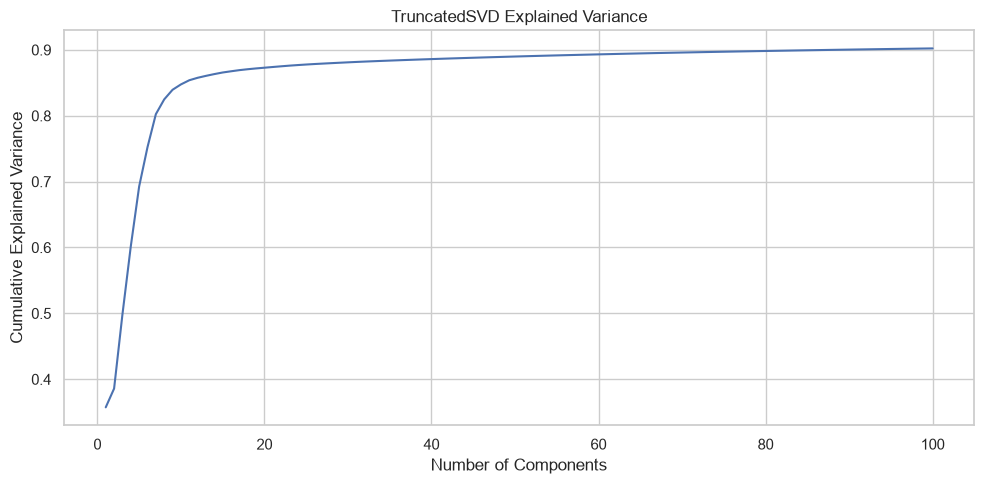

In [18]:
cumulative_variance = np.cumsum(
    svd.explained_variance_ratio_
)

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("TruncatedSVD Explained Variance")

plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
print("Reduced matrix shape:", X_reduced.shape)

print("Contains NaN:", np.isnan(X_reduced).any())
print("Contains infinity:", np.isinf(X_reduced).any())

print("Mean:", X_reduced.mean())
print("Standard deviation:", X_reduced.std())

Reduced matrix shape: (108671, 100)
Contains NaN: False
Contains infinity: False
Mean: 0.014621893673259887
Standard deviation: 0.31678882521614576


In [20]:
save_npz(
    OUTPUT_DIR / "X_combined.npz",
    X_combined
)

np.save(
    OUTPUT_DIR / "X_reduced.npy",
    X_reduced
)

np.save(
    OUTPUT_DIR / "X_num_scaled.npy",
    X_num_scaled
)

np.save(
    OUTPUT_DIR / "y_true.npy",
    df_clean["label"].to_numpy()
)

np.save(
    OUTPUT_DIR / "source.npy",
    df_clean["source"].to_numpy()
)

joblib.dump(
    tfidf,
    OUTPUT_DIR / "tfidf_vectorizer.joblib"
)

joblib.dump(
    scaler,
    OUTPUT_DIR / "numerical_scaler.joblib"
)

joblib.dump(
    encoder,
    OUTPUT_DIR / "categorical_encoder.joblib"
)

joblib.dump(
    svd,
    OUTPUT_DIR / "svd_model.joblib"
)

joblib.dump(
    numerical_columns,
    OUTPUT_DIR / "numerical_columns.joblib"
)

joblib.dump(
    categorical_columns,
    OUTPUT_DIR / "categorical_columns.joblib"
)

print("All preprocessing outputs saved successfully!")

All preprocessing outputs saved successfully!


In [21]:
print("PREPROCESSING SUMMARY")
print("---------------------")

print("Total emails:", len(df_clean))
print("TF-IDF features:", X_text.shape[1])
print("Numerical features:", X_num_scaled.shape[1])
print("Categorical features:", X_cat_encoded.shape[1])

print("Combined features:", X_combined.shape[1])
print("Reduced dimensions:", X_reduced.shape[1])

print(
    "Explained variance:",
    round(explained_variance * 100, 2),
    "%"
)

print("\nPreprocessing completed successfully!")

PREPROCESSING SUMMARY
---------------------
Total emails: 108671
TF-IDF features: 5000
Numerical features: 7
Categorical features: 522
Combined features: 5529
Reduced dimensions: 100
Explained variance: 90.22 %

Preprocessing completed successfully!
